# Dogs vs Cats Binary Classification using a CNN (PyTorch)

Goal: highest **macro F1** on the test set. (The original title said RNN, but the model is a CNN.)

## 1. Import Libraries

In [1]:
import os
import copy
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets
import torchvision.transforms.v2 as v2

from sklearn.metrics import confusion_matrix, classification_report, f1_score, accuracy_score

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


## 2. Dataset Paths

In [2]:
data_dir = '/kaggle/input/datasets/blourdhuraju/dogs-vs-cats-classification/dogs-vs-cats-classification'
train_path = data_dir + '/train'
valid_path = data_dir + '/validation'
test_path  = data_dir + '/test'

## 3. Show Random Sample Images

Number of classes: 2


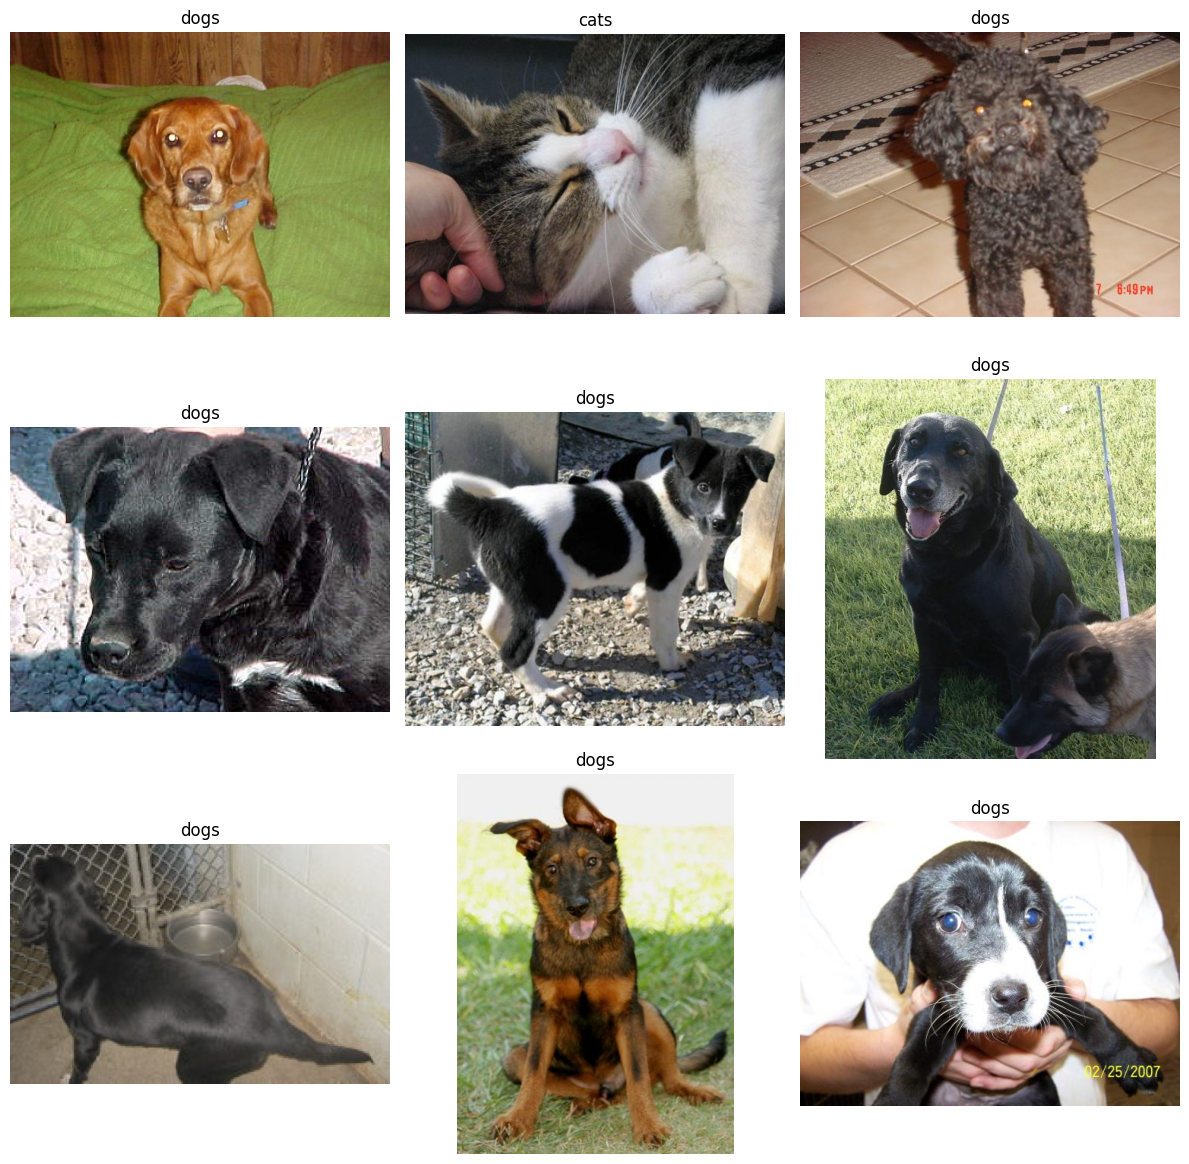

In [3]:
classes = os.listdir(train_path)
print(f"Number of classes: {len(classes)}")

plt.figure(figsize=(12, 12))
for i in range(9):
    class_name = random.choice(classes)
    class_path = os.path.join(train_path, class_name)
    image_name = random.choice(os.listdir(class_path))
    img = Image.open(os.path.join(class_path, image_name))
    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    plt.title(class_name)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 4. Inspect Image Sizes per Class

In [4]:
for class_name in classes:
    class_path = os.path.join(train_path, class_name)
    image_name = random.choice(os.listdir(class_path))
    img = Image.open(os.path.join(class_path, image_name))
    print(f"Class: {class_name}")
    print(f"Number of images: {len(os.listdir(class_path))}")
    print(f"Image Name: {image_name}")
    print(f"Width x Height: {img.size}")
    print("-" * 40)

Class: cats
Number of images: 9977
Image Name: cat_train_04662.jpg
Width x Height: (500, 375)
----------------------------------------
Class: dogs
Number of images: 9966
Image Name: dog_train_01168.jpg
Width x Height: (400, 500)
----------------------------------------


## 5. Image Transforms (Augmentation for Train Only)

In [5]:
IMG_SIZE = 224
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_transform = v2.Compose([
    v2.Resize((IMG_SIZE, IMG_SIZE)),
    v2.RandomHorizontalFlip(),
    v2.RandomRotation(15),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean, std),
])

eval_transform = v2.Compose([
    v2.Resize((IMG_SIZE, IMG_SIZE)),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean, std),
])

## 6. Create Datasets

In [6]:
train_dataset = datasets.ImageFolder(train_path, transform=train_transform)
valid_dataset = datasets.ImageFolder(valid_path, transform=eval_transform)
test_dataset  = datasets.ImageFolder(test_path,  transform=eval_transform)
class_names = train_dataset.classes

print(f"Train Images      : {len(train_dataset)}")
print(f"Validation Images : {len(valid_dataset)}")
print(f"Test Images       : {len(test_dataset)}")
print(train_dataset.class_to_idx)

Train Images      : 19943
Validation Images : 2492
Test Images       : 2495
{'cats': 0, 'dogs': 1}


## 7. Check Class Balance

Train {'cats': 9977, 'dogs': 9966}
Validation {'cats': 1247, 'dogs': 1245}
Test {'cats': 1248, 'dogs': 1247}


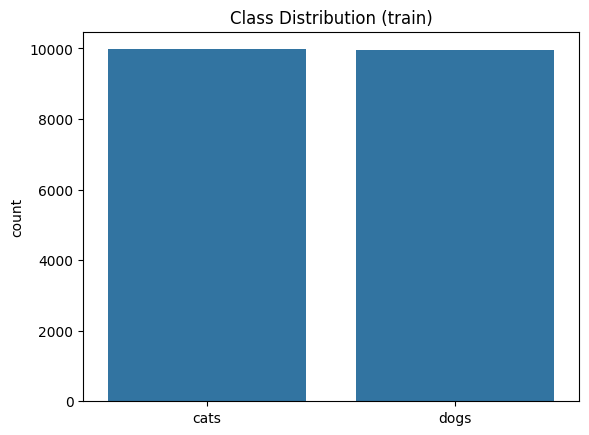

In [7]:
for name, ds in [("Train", train_dataset), ("Validation", valid_dataset), ("Test", test_dataset)]:
    counts = Counter(ds.targets)
    print(name, {class_names[k]: v for k, v in sorted(counts.items())})

sns.countplot(x=[class_names[t] for t in train_dataset.targets])
plt.title("Class Distribution (train)")
plt.show()

## 8. Check Shape and Augmentation of One Image

torch.Size([3, 224, 224])


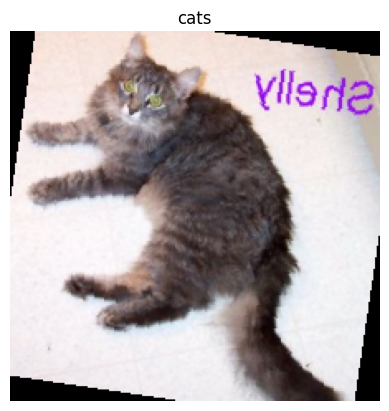

In [8]:
image, label = train_dataset[0]
print(image.shape)

# undo the normalization so the colors display correctly
show = (image * torch.tensor(std).view(3, 1, 1) + torch.tensor(mean).view(3, 1, 1)).clamp(0, 1)

plt.imshow(show.permute(1, 2, 0))
plt.title(class_names[label])
plt.axis("off")
plt.show()

## 9. Data Loaders

In [9]:
BATCH_SIZE = 32

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

xb, yb = next(iter(train_loader))
print(xb.shape, yb.shape)   # [32, 3, 224, 224] [32]

torch.Size([32, 3, 224, 224]) torch.Size([32])


## 10. Build the CNN Model

In [10]:
class CNNModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),     # 224 -> 112

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),     # 112 -> 56

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),    # 56 -> 28

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256), nn.ReLU(), nn.MaxPool2d(2),    # 28 -> 14
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 14 * 14, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 1),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = CNNModel().to(device)
print(model)

CNNModel(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)


## 11. Loss, Optimizer and Scheduler

In [11]:
PATIENCE = 5
LR = 1e-3

criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=2, min_lr=1e-6
)

## 12. Train / Validation Function (run_epoch)

In [12]:
def run_epoch(loader, train=False):
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    all_preds, all_labels = [], []

    with torch.set_grad_enabled(train):
        for images, labels in loader:
            images = images.to(device)
            labels = labels.float().unsqueeze(1).to(device)

            output = model(images)
            loss = criterion(output, labels)

            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * len(labels)
            preds = (torch.sigmoid(output) >= 0.5).int()
            correct += (preds == labels.int()).sum().item()
            n += len(labels)
            all_preds.extend(preds.cpu().flatten().tolist())
            all_labels.extend(labels.cpu().int().flatten().tolist())

    avg_loss = total_loss / n
    acc = correct / n
    macro_f1 = f1_score(all_labels, all_preds, average="macro")
    return avg_loss, acc, macro_f1, all_preds, all_labels

## 13. Early Stopping Class (keeps the best model)

In [13]:
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.0, mode='max'):
        self.patience = patience
        self.min_delta = min_delta
        self.mode = mode
        self.counter = 0
        self.best_score = -float('inf') if mode == 'max' else float('inf')
        self.best_state = None
        self.early_stop = False

    def _improved(self, score):
        if self.mode == 'max':
            return score > self.best_score + self.min_delta
        return score < self.best_score - self.min_delta

    def __call__(self, score, model):
        if self._improved(score):
            self.best_score = score
            self.best_state = copy.deepcopy(model.state_dict())
            self.counter = 0
        else:
            self.counter += 1
            print(f"EarlyStopping counter: {self.counter} out of {self.patience}")
            if self.counter >= self.patience:
                self.early_stop = True

## 14. Train the Model

In [14]:
epochs = 30
early_stopping = EarlyStopping(patience=PATIENCE, mode='max')   # monitors validation macro F1
history = {"loss": [], "acc": [], "f1": [], "val_loss": [], "val_acc": [], "val_f1": []}

for epoch in range(1, epochs + 1):
    tr_loss, tr_acc, tr_f1, _, _ = run_epoch(train_loader, train=True)
    va_loss, va_acc, va_f1, _, _ = run_epoch(valid_loader, train=False)

    scheduler.step(va_f1)

    history["loss"].append(tr_loss);     history["acc"].append(tr_acc);     history["f1"].append(tr_f1)
    history["val_loss"].append(va_loss); history["val_acc"].append(va_acc); history["val_f1"].append(va_f1)

    print(f"Epoch {epoch:02d}/{epochs} | "
          f"Loss {tr_loss:.4f} Acc {tr_acc:.4f} F1 {tr_f1:.4f} | "
          f"Val Loss {va_loss:.4f} Val Acc {va_acc:.4f} Val F1 {va_f1:.4f} | "
          f"LR {optimizer.param_groups[0]['lr']:.6f}")

    early_stopping(va_f1, model)
    if early_stopping.early_stop:
        print("Early stopping triggered! Stopping training to prevent overfitting.")
        break

model.load_state_dict(early_stopping.best_state)
print(f"Best validation macro F1: {early_stopping.best_score:.4f}")

Epoch 01/30 | Loss 0.9201 Acc 0.5942 F1 0.5910 | Val Loss 0.6213 Val Acc 0.6561 Val F1 0.6451 | LR 0.001000
Epoch 02/30 | Loss 0.5906 Acc 0.6764 F1 0.6721 | Val Loss 0.5321 Val Acc 0.7195 Val F1 0.7173 | LR 0.001000
Epoch 03/30 | Loss 0.5466 Acc 0.7160 F1 0.7125 | Val Loss 0.4769 Val Acc 0.7761 Val F1 0.7749 | LR 0.001000
Epoch 04/30 | Loss 0.5174 Acc 0.7536 F1 0.7524 | Val Loss 0.5040 Val Acc 0.7508 Val F1 0.7404 | LR 0.001000
EarlyStopping counter: 1 out of 5
Epoch 05/30 | Loss 0.4773 Acc 0.7792 F1 0.7785 | Val Loss 0.3745 Val Acc 0.8242 Val F1 0.8226 | LR 0.001000
Epoch 06/30 | Loss 0.4511 Acc 0.8004 F1 0.7997 | Val Loss 0.4198 Val Acc 0.7881 Val F1 0.7820 | LR 0.001000
EarlyStopping counter: 1 out of 5
Epoch 07/30 | Loss 0.4259 Acc 0.8159 F1 0.8154 | Val Loss 0.3540 Val Acc 0.8230 Val F1 0.8193 | LR 0.001000
EarlyStopping counter: 2 out of 5
Epoch 08/30 | Loss 0.3953 Acc 0.8313 F1 0.8310 | Val Loss 0.3054 Val Acc 0.8644 Val F1 0.8638 | LR 0.001000
Epoch 09/30 | Loss 0.3702 Acc 0.84

## 15. Plot Training Curves

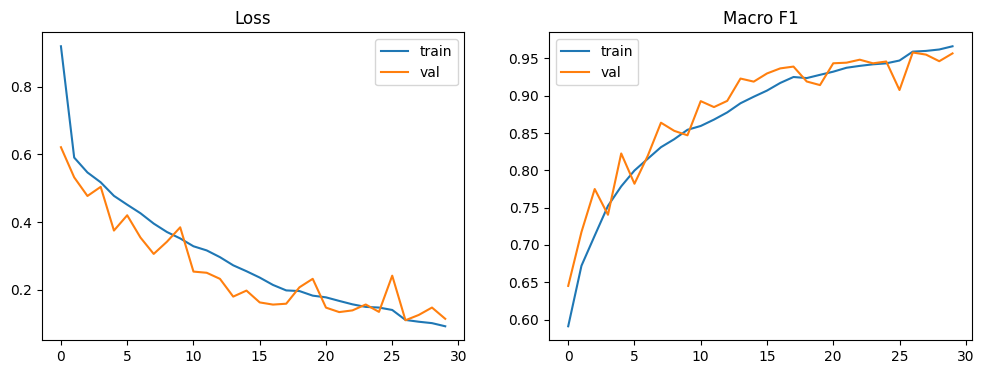

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history["loss"], label="train"); ax[0].plot(history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history["f1"], label="train"); ax[1].plot(history["val_f1"], label="val")
ax[1].set_title("Macro F1"); ax[1].legend()
plt.show()

## 16. Test the Best Model

In [16]:
test_loss, test_acc, test_f1, test_preds, test_labels = run_epoch(test_loader, train=False)
print("Loss     :", test_loss)
print("Accuracy :", test_acc)
print("Macro F1 :", test_f1)

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Loss     : 0.1270646807903756
Accuracy : 0.9507014028056112
Macro F1 : 0.9507006108507332


## 17. Classification Report and Confusion Matrix

              precision    recall  f1-score   support

        cats       0.95      0.95      0.95      1248
        dogs       0.95      0.96      0.95      1247

    accuracy                           0.95      2495
   macro avg       0.95      0.95      0.95      2495
weighted avg       0.95      0.95      0.95      2495



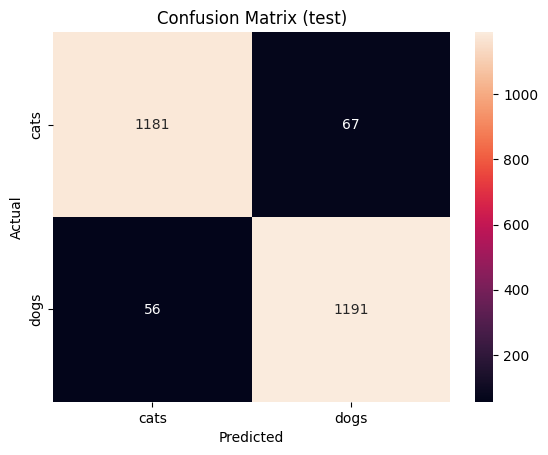

In [17]:
print(classification_report(test_labels, test_preds, target_names=class_names))

cm = confusion_matrix(test_labels, test_preds)
sns.heatmap(cm, annot=True, fmt="d", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (test)")
plt.show()

## 18. False Positive Rate

In [18]:
tn, fp, fn, tp = cm.ravel()
fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
print(f"Positive class = '{class_names[1]}'")
print(f"False Positive Rate (FPR): {fpr:.4f}")

Positive class = 'dogs'
False Positive Rate (FPR): 0.0537


## 19. Save the Model

In [19]:
torch.save(model.state_dict(), "best_cnn_model.pth")

torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "best_val_f1": early_stopping.best_score,
    "history": history,
    "class_names": class_names,
}, "checkpoint.pth")

print("Best model and checkpoint saved successfully!")

Best model and checkpoint saved successfully!
